In [119]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score
)
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    average_precision_score
)
from imblearn.over_sampling import SMOTE
import joblib
import json
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import roc_curve, roc_auc_score

In [120]:
!pip install imbalanced-learn

In [121]:
df = pd.read_csv(r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\data\creditcard.csv")

In [122]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [123]:
df.shape

(284807, 31)

In [124]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [125]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [126]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [127]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [128]:
df['Class'].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [129]:
output_path = r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\images"
os.makedirs(output_path, exist_ok=True)

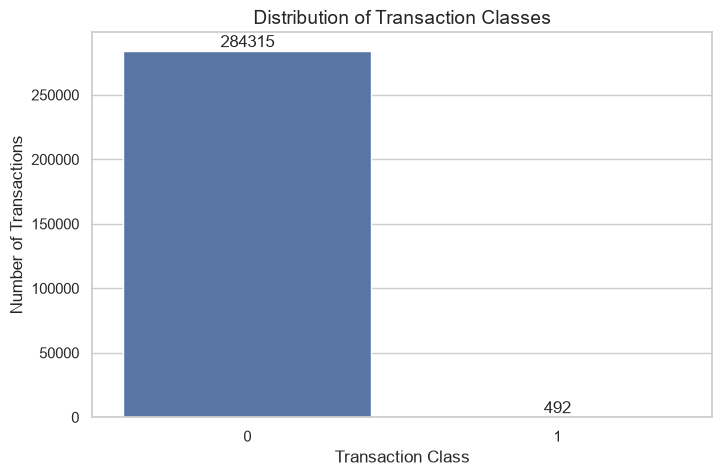

In [130]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Class')
plt.title('Distribution of Transaction Classes', fontsize=14)
plt.xlabel('Transaction Class', fontsize=12)
plt.ylabel('Number of Transactions', fontsize=12)
for container in ax.containers:
    ax.bar_label(container)
plt.savefig(os.path.join(output_path, 'class_distribution.png'),dpi=300,bbox_inches='tight')
plt.show()
plt.close()

In [131]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


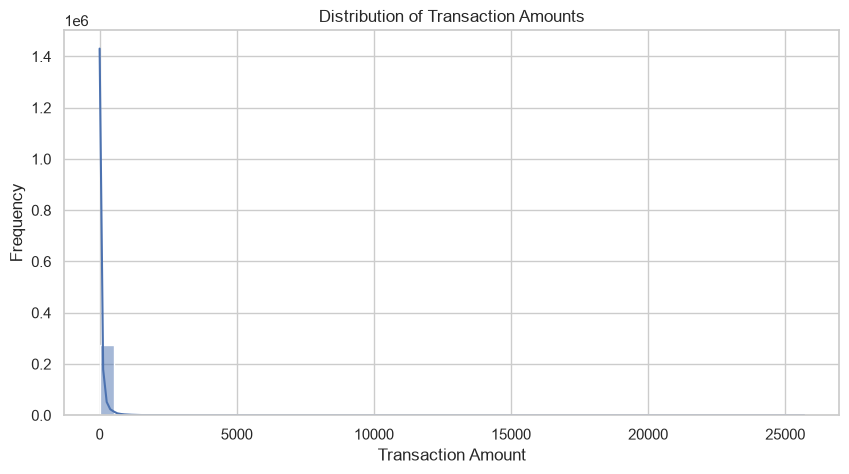

In [132]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Amount', bins=50, kde=True)

plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.savefig(
    os.path.join(output_path, 'amount_distribution.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

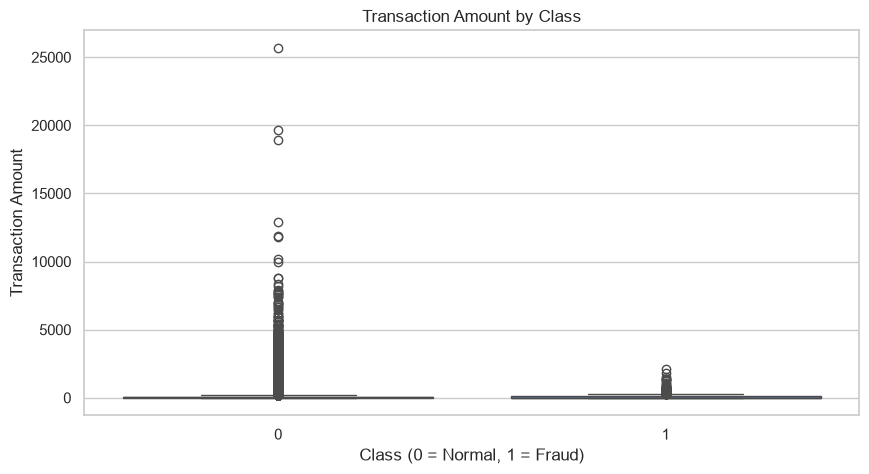

In [133]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='Class', y='Amount')

plt.title('Transaction Amount by Class')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Transaction Amount')

plt.savefig(
    os.path.join(output_path, 'amount_by_class.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

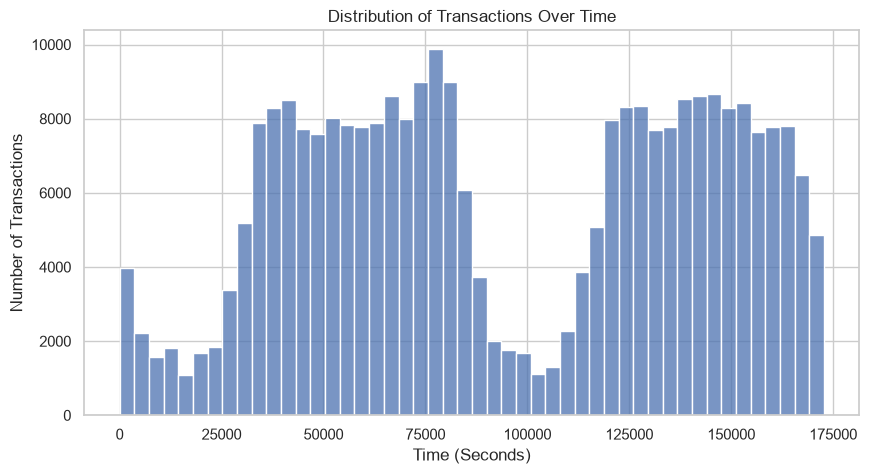

In [134]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='Time', bins=48)

plt.title('Distribution of Transactions Over Time')
plt.xlabel('Time (Seconds)')
plt.ylabel('Number of Transactions')

plt.savefig(
    os.path.join(output_path, 'time_distribution.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

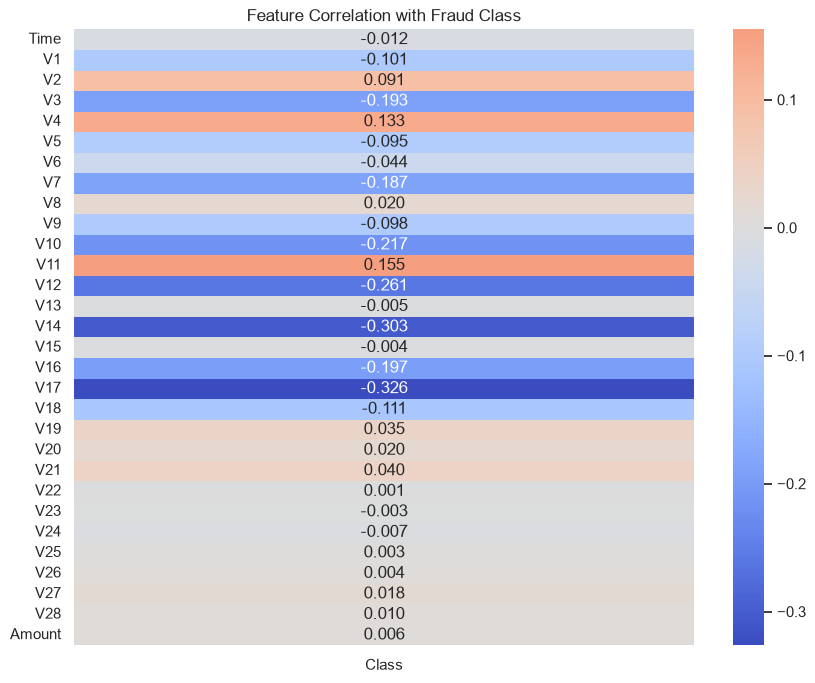

In [135]:
class_corr = df.corr(numeric_only=True)['Class'].drop('Class')

plt.figure(figsize=(10, 8))

sns.heatmap(
    class_corr.to_frame(),
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.3f'
)

plt.title('Feature Correlation with Fraud Class')

plt.savefig(
    os.path.join(output_path, 'class_correlation.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()
plt.close()

In [136]:
df.duplicated().sum()

np.int64(1081)

In [137]:
df.isnull().sum().sum()

np.int64(0)

In [138]:
duplicate_analysis = df[df.duplicated(keep=False)]

duplicate_analysis['Class'].value_counts()

Class
0    1822
1      32
Name: count, dtype: int64

In [139]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [140]:
df_raw = df.copy()

In [141]:
df_clean = df_raw.drop_duplicates().copy()

In [142]:
print("Original Dataset:", df_raw.shape)
print("Cleaned Dataset:", df_clean.shape)

Original Dataset: (284807, 31)
Cleaned Dataset: (283726, 31)


In [143]:
print("Original Class Distribution:")
print(df_raw['Class'].value_counts())

print("\nCleaned Class Distribution:")
print(df_clean['Class'].value_counts())

Original Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Cleaned Class Distribution:
Class
0    283253
1       473
Name: count, dtype: int64


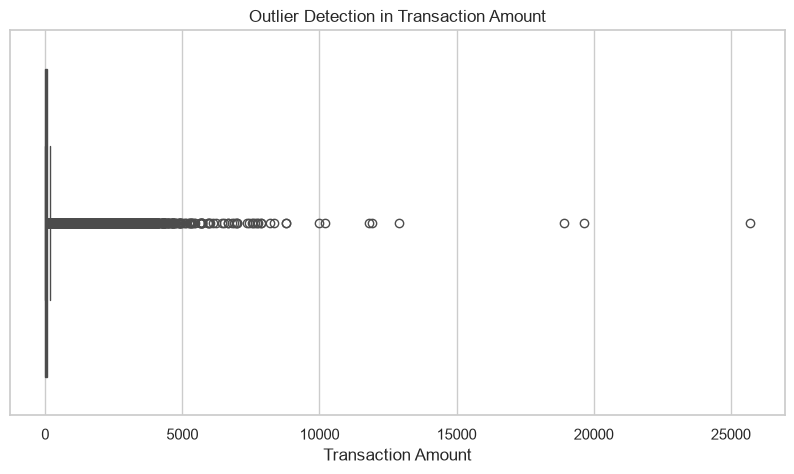

In [144]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_clean['Amount'])

plt.title('Outlier Detection in Transaction Amount')
plt.xlabel('Transaction Amount')

plt.show()

In [145]:
Q1 = df_clean['Amount'].quantile(0.25)
Q3 = df_clean['Amount'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean['Amount'] < lower_bound) |
    (df_clean['Amount'] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Lower Bound: -102.26500000000001
Upper Bound: 185.375
Number of Outliers: 31685


In [146]:
outliers['Class'].value_counts()

Class
0    31598
1       87
Name: count, dtype: int64

In [147]:
outliers['Class'].value_counts(normalize=True) * 100

Class
0    99.725422
1     0.274578
Name: proportion, dtype: float64

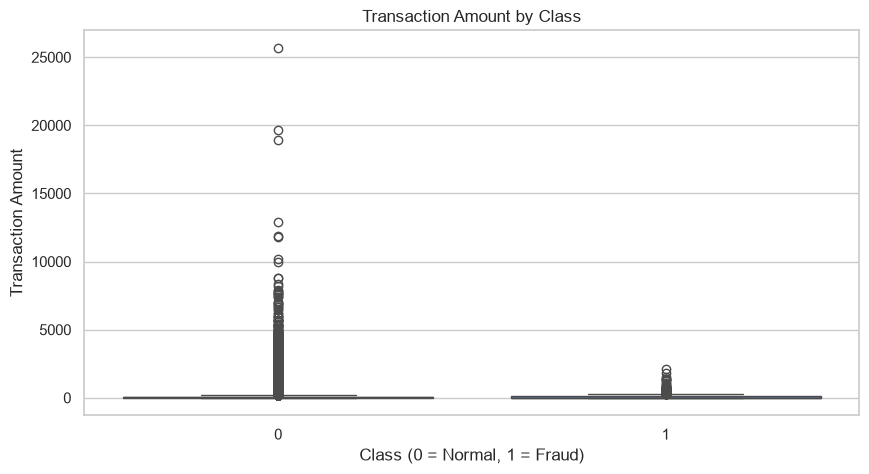

In [148]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_clean,
    x='Class',
    y='Amount'
)

plt.title('Transaction Amount by Class')
plt.xlabel('Class (0 = Normal, 1 = Fraud)')
plt.ylabel('Transaction Amount')

plt.show()

In [149]:
correlation = df_clean.corr()

correlation_with_class = correlation['Class'].sort_values(
    ascending=False
)

print(correlation_with_class)

Class     1.000000
V11       0.149067
V4        0.129326
V2        0.084624
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
V28       0.009682
Amount    0.005777
V22       0.004887
V26       0.004265
V25       0.003202
V15      -0.003300
V13      -0.003897
V23      -0.006333
V24      -0.007210
Time     -0.012359
V6       -0.043915
V5       -0.087812
V9       -0.094021
V1       -0.094486
V18      -0.105340
V7       -0.172347
V3       -0.182322
V16      -0.187186
V10      -0.206971
V12      -0.250711
V14      -0.293375
V17      -0.313498
Name: Class, dtype: float64


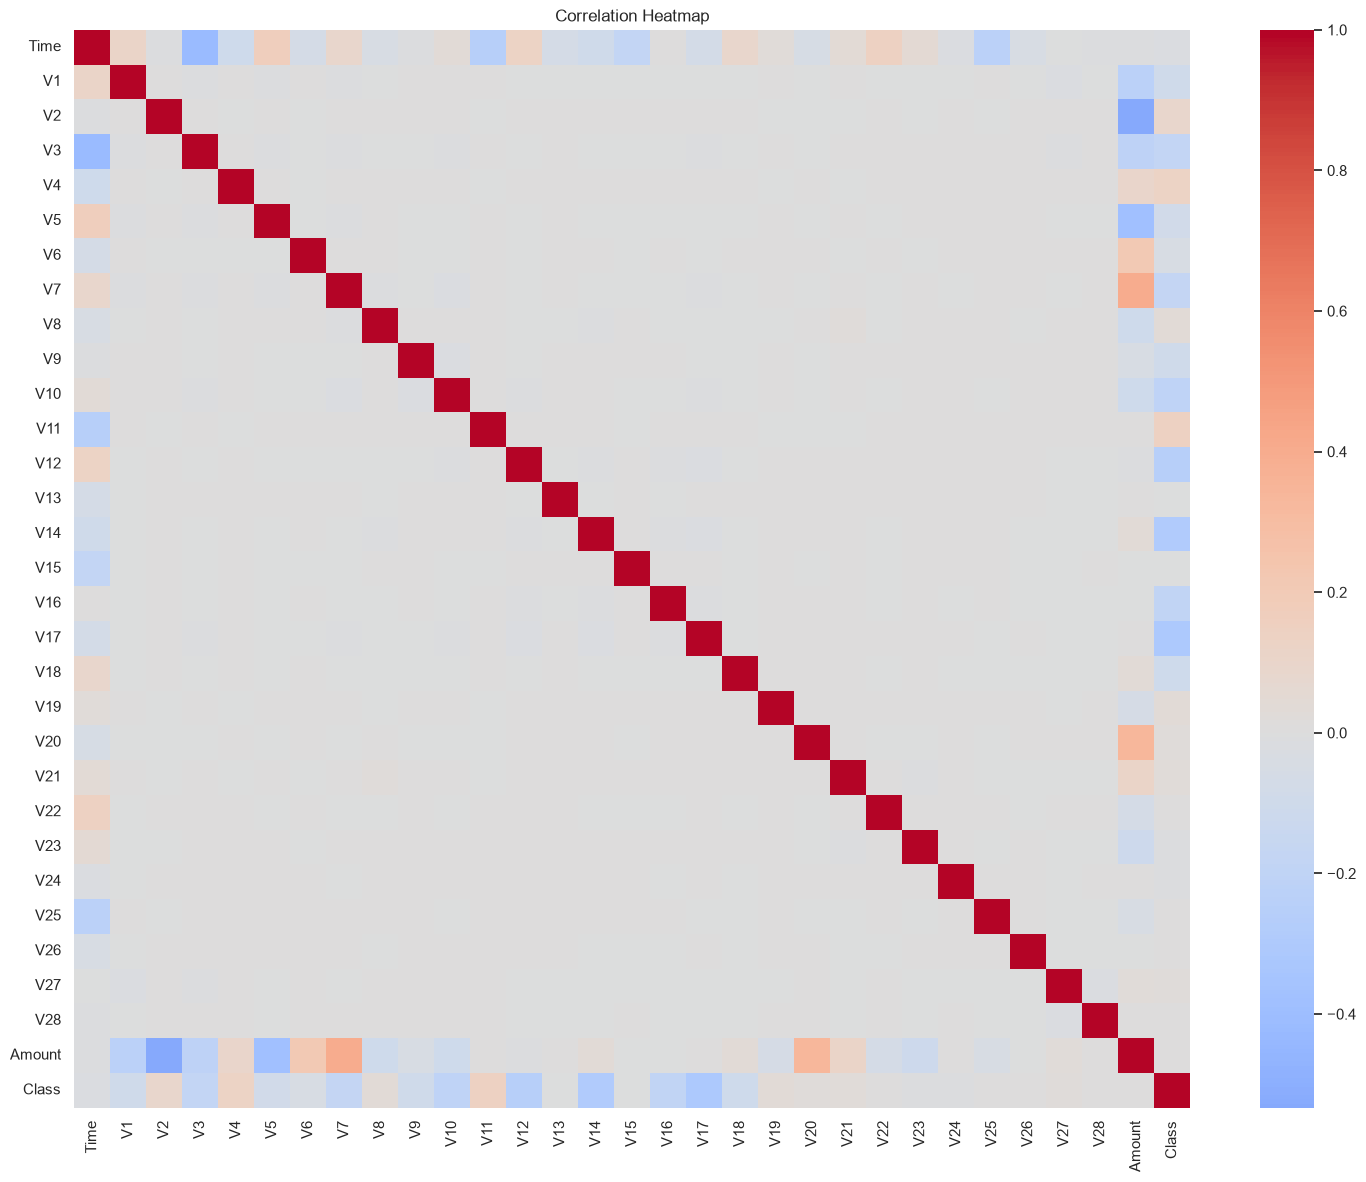

In [186]:
plt.figure(figsize=(18, 14))

sns.heatmap(
    df_clean.corr(),
    cmap='coolwarm',
    center=0
)
plt.title('Correlation Heatmap')
plt.savefig(
    os.path.join(
        r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\images",
        "Correlation Heatmap.png"
    ),
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [151]:
X = df_clean.drop('Class', axis=1)

y = df_clean['Class']

In [152]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [153]:
X[['Time', 'Amount']].describe()

,Time,Amount
count,283726.000000,283726.000000
mean,94811.077600,88.472687
std,47481.047891,250.399437
min,0.000000,0.000000
25%,54204.750000,5.600000
50%,84692.500000,22.000000
75%,139298.000000,77.510000
max,172792.000000,25691.160000


In [154]:
X.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,0.000187,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.769984,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-54.497720,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.211469,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.062353,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.133207,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,39.420904,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000


In [155]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (198608, 30)
Validation: (42559, 30)
Test: (42559, 30)


In [156]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (198608, 30)
Validation: (42559, 30)
Test: (42559, 30)


In [157]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training class distribution:
Class
0    198277
1       331
Name: count, dtype: int64

Training class percentages:
Class
0    99.83334
1     0.16666
Name: proportion, dtype: float64


In [158]:
output_path = r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\data"
os.makedirs(output_path, exist_ok=True)

np.save(os.path.join(output_path, "X_train_scaled.npy"), X_train_scaled)
np.save(os.path.join(output_path, "X_test_scaled.npy"), X_test_scaled)
np.save(os.path.join(output_path, "y_train.npy"), y_train.to_numpy())
np.save(os.path.join(output_path, "y_test.npy"), y_test.to_numpy())

print("Preprocessed data saved successfully!")

Preprocessed data saved successfully!


In [159]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_val_probabilities = lr_model.predict_proba(X_val_scaled)[:, 1]

In [160]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

rf_val_probabilities = rf_model.predict_proba(X_val_scaled)[:, 1]

In [162]:
lr_predictions = lr_model.predict(X_test_scaled)
lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]
rf_predictions = rf_model.predict(X_test_scaled)
rf_probabilities = rf_model.predict_proba(X_test_scaled)[:, 1]
print("===== Logistic Regression =====")
print(classification_report(y_test, lr_predictions, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))
print("PR-AUC:", average_precision_score(y_test, lr_probabilities))
print("ROC-AUC:", roc_auc_score(y_test, lr_probabilities))
print("\n===== Random Forest =====")
print(classification_report(y_test, rf_predictions, zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))
print("PR-AUC:", average_precision_score(y_test, rf_probabilities))
print("ROC-AUC:", roc_auc_score(y_test, rf_probabilities))

===== Logistic Regression =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42488
           1       0.85      0.62      0.72        71

    accuracy                           1.00     42559
   macro avg       0.92      0.81      0.86     42559
weighted avg       1.00      1.00      1.00     42559

Confusion Matrix:
[[42480     8]
 [   27    44]]
PR-AUC: 0.7237928769853385
ROC-AUC: 0.9643097239054739

===== Random Forest =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42488
           1       0.93      0.77      0.85        71

    accuracy                           1.00     42559
   macro avg       0.97      0.89      0.92     42559
weighted avg       1.00      1.00      1.00     42559

Confusion Matrix:
[[42484     4]
 [   16    55]]
PR-AUC: 0.7900192000619418
ROC-AUC: 0.9723840832606256


In [163]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    'Precision': [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    'F1-Score': [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],
    'PR-AUC': [
        average_precision_score(y_test, lr_probabilities),
        average_precision_score(y_test, rf_probabilities)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1-Score    PR-AUC
0  Logistic Regression  0.999178   0.846154  0.619718  0.715447  0.723793
1        Random Forest  0.999530   0.932203  0.774648  0.846154  0.790019


In [164]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Class
0    198277
1       331
Name: count, dtype: int64

After SMOTE:
Class
0    198277
1    198277
Name: count, dtype: int64


In [165]:
lr_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_smote.fit(X_train_smote, y_train_smote)

lr_smote_predictions = lr_smote.predict(X_test_scaled)
lr_smote_probabilities = lr_smote.predict_proba(X_test_scaled)[:, 1]

In [166]:
rf_smote = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_smote.fit(X_train_smote, y_train_smote)

rf_smote_predictions = rf_smote.predict(X_test_scaled)
rf_smote_probabilities = rf_smote.predict_proba(X_test_scaled)[:, 1]

In [167]:
print("===== Logistic Regression + SMOTE =====")
print(classification_report(y_test, lr_smote_predictions))
print(confusion_matrix(y_test, lr_smote_predictions))

print("\n===== Random Forest + SMOTE =====")
print(classification_report(y_test, rf_smote_predictions))
print(confusion_matrix(y_test, rf_smote_predictions))

===== Logistic Regression + SMOTE =====
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     42488
           1       0.05      0.87      0.09        71

    accuracy                           0.97     42559
   macro avg       0.52      0.92      0.54     42559
weighted avg       1.00      0.97      0.98     42559

[[41299  1189]
 [    9    62]]

===== Random Forest + SMOTE =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42488
           1       0.51      0.83      0.63        71

    accuracy                           1.00     42559
   macro avg       0.75      0.91      0.82     42559
weighted avg       1.00      1.00      1.00     42559

[[42431    57]
 [   12    59]]


In [168]:
models_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Logistic Regression + SMOTE',
        'Random Forest + SMOTE'
    ],
    'Precision': [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, rf_predictions),
        precision_score(y_test, lr_smote_predictions),
        precision_score(y_test, rf_smote_predictions)
    ],
    'Recall': [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, rf_predictions),
        recall_score(y_test, lr_smote_predictions),
        recall_score(y_test, rf_smote_predictions)
    ],
    'F1-Score': [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, rf_predictions),
        f1_score(y_test, lr_smote_predictions),
        f1_score(y_test, rf_smote_predictions)
    ],
    'PR-AUC': [
        average_precision_score(y_test, lr_probabilities),
        average_precision_score(y_test, rf_probabilities),
        average_precision_score(y_test, lr_smote_probabilities),
        average_precision_score(y_test, rf_smote_probabilities)
    ]
})

print(models_results.round(4))

                         Model  Precision  Recall  F1-Score  PR-AUC
0          Logistic Regression     0.8462  0.6197    0.7154  0.7238
1                Random Forest     0.9322  0.7746    0.8462  0.7900
2  Logistic Regression + SMOTE     0.0496  0.8732    0.0938  0.6872
3        Random Forest + SMOTE     0.5086  0.8310    0.6310  0.7814


In [169]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

threshold_results = []

for threshold in thresholds:

    predictions = (rf_probabilities >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-Score': f1_score(y_test, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   Threshold  Precision  Recall  F1-Score
0        0.1     0.7467  0.7887    0.7671
1        0.2     0.8235  0.7887    0.8058
2        0.3     0.8615  0.7887    0.8235
3        0.4     0.9322  0.7746    0.8462
4        0.5     0.9322  0.7746    0.8462
5        0.6     0.9636  0.7465    0.8413


In [170]:

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]

results = []

for threshold in thresholds:

    predictions = (rf_val_probabilities >= threshold).astype(int)

    precision = precision_score(y_val, predictions)
    recall = recall_score(y_val, predictions)
    f1 = f1_score(y_val, predictions)

    results.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

threshold_results = pd.DataFrame(results)

threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.1,0.840580,0.816901,0.828571
1,0.2,0.890625,0.802817,0.844444
2,0.3,0.919355,0.802817,0.857143
3,0.4,0.949153,0.788732,0.861538
4,0.5,0.982456,0.788732,0.875000
5,0.6,1.000000,0.718310,0.836066


In [171]:
best_threshold = 0.5

In [172]:
rf_test_probabilities = rf_model.predict_proba(X_test_scaled)[:, 1]
rf_test_predictions = (rf_test_probabilities >= best_threshold).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_test_predictions,
    target_names=['Normal', 'Fraud']
))

Confusion Matrix:
[[42484     4]
 [   16    55]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     42488
       Fraud       0.93      0.77      0.85        71

    accuracy                           1.00     42559
   macro avg       0.97      0.89      0.92     42559
weighted avg       1.00      1.00      1.00     42559



In [173]:
model_path = r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\models"
os.makedirs(model_path, exist_ok=True)
joblib.dump(rf_model, os.path.join(model_path, "random_forest.pkl"))
joblib.dump(scaler, os.path.join(model_path, "scaler.pkl"))

model_settings = {
    "model": "Random Forest",
    "threshold": best_threshold,
    "scaling": "StandardScaler"
}

with open(os.path.join(model_path, "model_settings.json"), "w") as file:
    json.dump(model_settings, file, indent=4)

print("Model, Scaler and Settings saved successfully!")

Model, Scaler and Settings saved successfully!


In [174]:
loaded_model = joblib.load(os.path.join(model_path, "random_forest.pkl"))
loaded_scaler = joblib.load(os.path.join(model_path, "scaler.pkl"))

with open(os.path.join(model_path, "model_settings.json"), "r") as file:
    loaded_settings = json.load(file)

loaded_threshold = loaded_settings["threshold"]

print("Model loaded:", loaded_model is not None)
print("Scaler loaded:", loaded_scaler is not None)
print("Threshold:", loaded_threshold)

Model loaded: True
Scaler loaded: True
Threshold: 0.5


In [175]:
# Select test samples
sample_data = X_test.iloc[:10]
# Scale test samples
sample_scaled = loaded_scaler.transform(sample_data)
# Predict probabilities
sample_probabilities = loaded_model.predict_proba(sample_scaled)[:, 1]
# Apply saved threshold
sample_predictions = (sample_probabilities >= loaded_threshold).astype(int)
# Compare with actual labels
sample_results = pd.DataFrame({
    'Actual': y_test.iloc[:10].values,
    'Predicted': sample_predictions,
    'Fraud_Probability': sample_probabilities
})
sample_results

,Actual,Predicted,Fraud_Probability
0,1,0,0.000361
1,0,0,0.000130
2,0,0,0.000142
3,0,0,0.000312
4,0,0,0.000148
5,0,0,0.000128
6,0,0,0.000273
7,0,0,0.000147
8,0,0,0.002322
9,0,0,0.000158


In [176]:
fraud_index = y_test[y_test == 1].index[0]

fraud_sample = X_test.loc[[fraud_index]]

fraud_scaled = loaded_scaler.transform(fraud_sample)

fraud_probability = loaded_model.predict_proba(fraud_scaled)[0, 1]

fraud_prediction = int(fraud_probability >= loaded_threshold)

print("Actual Class:", y_test.loc[fraud_index])
print("Predicted Class:", fraud_prediction)
print("Fraud Probability:", fraud_probability)

Actual Class: 1
Predicted Class: 0
Fraud Probability: 0.0003605098369135971


In [177]:
sample_data = X_test.iloc[:5]

sample_scaled = loaded_scaler.transform(sample_data)

sample_probabilities = loaded_model.predict_proba(sample_scaled)[:, 1]

sample_predictions = (sample_probabilities >= 0.4).astype(int)

print("Predicted probabilities:", sample_probabilities)
print("Predicted classes:", sample_predictions)
print("Actual classes:", y_test.iloc[:5].values)

Predicted probabilities: [0.00036051 0.00012996 0.00014248 0.00031158 0.00014766]
Predicted classes: [0 0 0 0 0]
Actual classes: [1 0 0 0 0]


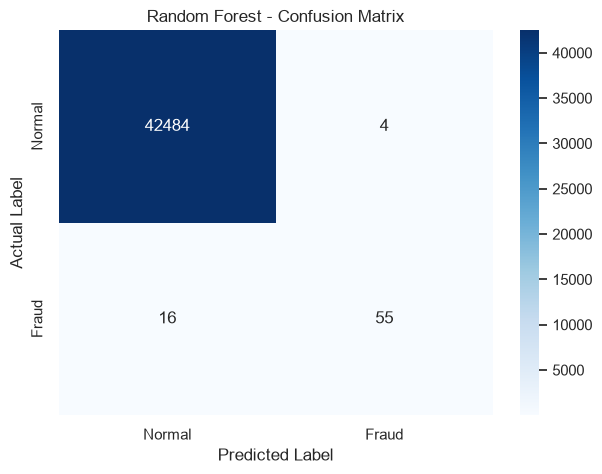

In [179]:
cm = confusion_matrix(y_test, rf_test_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Fraud'],
    yticklabels=['Normal', 'Fraud']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Random Forest - Confusion Matrix')

plt.savefig(
    os.path.join(
        r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\images",
        "confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

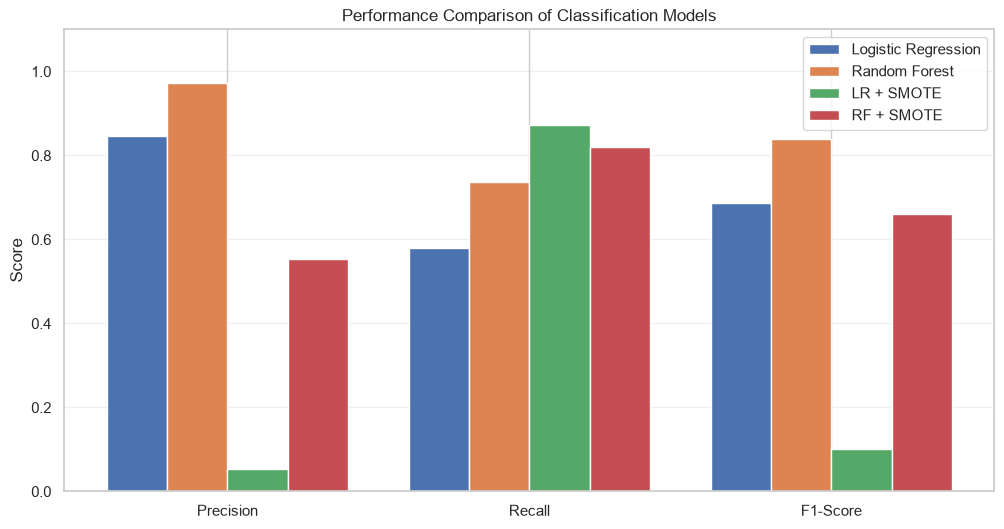

In [180]:
metrics = ['Precision', 'Recall', 'F1-Score']
models = [
    'Logistic Regression',
    'Random Forest',
    'LR + SMOTE',
    'RF + SMOTE'
]
values = [
    [0.8462, 0.5789, 0.6875],
    [0.9722, 0.7368, 0.8383],
    [0.0530, 0.8737, 0.1000],
    [0.5532, 0.8211, 0.6610]
]
x = np.arange(len(metrics))
width = 0.2
plt.figure(figsize=(12, 6))
for i, model in enumerate(models):
    plt.bar(
        x + (i - 1.5) * width,
        values[i],
        width,
        label=model
    )
plt.xticks(x, metrics)
plt.ylabel('Score')
plt.title('Performance Comparison of Classification Models')
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.savefig(os.path.join(r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\images","model_comparison.png" ),dpi=300,bbox_inches='tight')
plt.show()

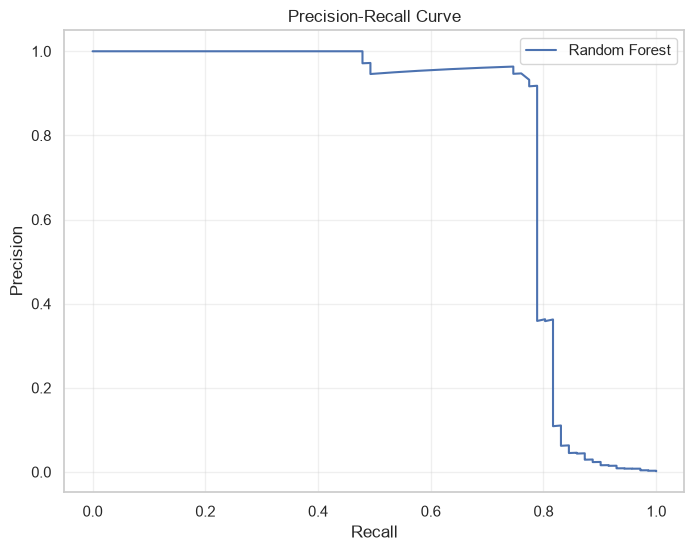

In [181]:
precision, recall, thresholds = precision_recall_curve(
    y_test,
    rf_probabilities
)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label='Random Forest')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\images","precision_recall_curve.png"),dpi=300,bbox_inches='tight')
plt.show()

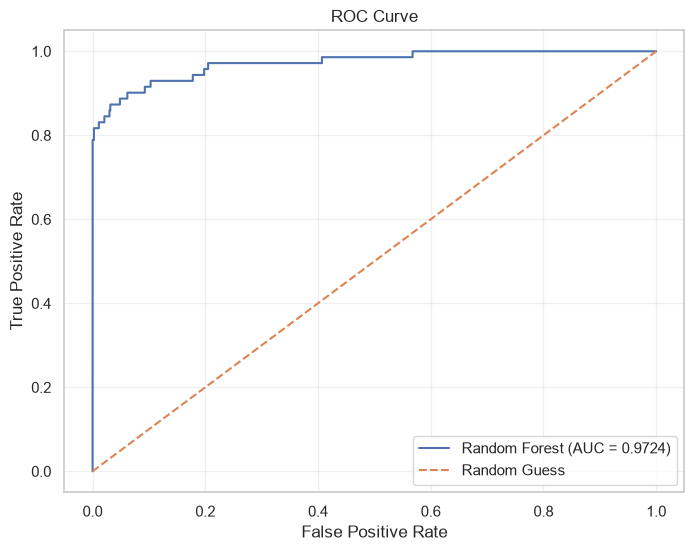

In [182]:
fpr, tpr, thresholds = roc_curve(y_test, rf_probabilities)
roc_auc = roc_auc_score(y_test, rf_probabilities)
plt.figure(figsize=(8, 6))
plt.plot(fpr,tpr,label=f'Random Forest (AUC = {roc_auc:.4f})')
plt.plot( [0, 1],[0, 1], linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\images", "roc_curve.png"),dpi=300,bbox_inches='tight')
plt.show()

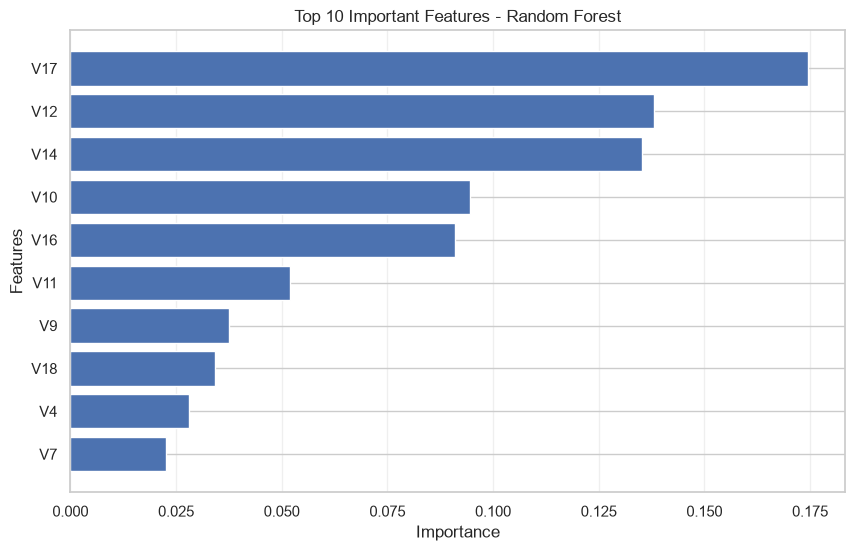

In [183]:
feature_importance = pd.DataFrame({'Feature': X.columns, 'Importance': rf_model.feature_importances_})
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
top_features = feature_importance.head(10)
plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Importance'])
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Top 10 Important Features - Random Forest')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.savefig(os.path.join(r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\images", "feature_importance.png"), dpi=300, bbox_inches='tight')
plt.show()

In [184]:
final_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'LR + SMOTE', 'RF + SMOTE'],
    'Precision': [0.8462, 0.9722, 0.0530, 0.5532],
    'Recall': [0.5789, 0.7368, 0.8737, 0.8211],
    'F1-Score': [0.6875, 0.8383, 0.1000, 0.6610],
    'PR-AUC': [0.6920, 0.7896, 0.6750, 0.7763]
})

final_results = final_results.sort_values(by='F1-Score', ascending=False)
final_results

,Model,Precision,Recall,F1-Score,PR-AUC
1,Random Forest,0.9722,0.7368,0.8383,0.7896
0,Logistic Regression,0.8462,0.5789,0.6875,0.6920
3,RF + SMOTE,0.5532,0.8211,0.6610,0.7763
2,LR + SMOTE,0.0530,0.8737,0.1000,0.6750


In [185]:
final_results.to_csv( r"C:\Users\USER\Desktop\Credit_Card_Fraud_Detection\final_model_results.csv",index=False)